# Домашнее задание 1: персональные top-10 рекомендации

Акопян Микаэла, группа 517.

Используется [Amazon Reviews 2018, Video Games, 5-core](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).
Категория включает игры, консоли, аксессуары. В отзыве указаны пользователь, товар, оценка от 1 до 5 и дата

Задача — рекомендовать пользователю 10 товаров, с которыми он ещё не взаимодействовал. Релевантными считаются товары с оценкой 4-5. Оценки 1-3 сохраняются для обучения и исключения известных товаров. Отсутствие отзыва не означает отрицательную оценку

Зависимости: `python -m pip install -r requirements.txt`
Данные: `python scripts/download_data.py` 

In [1]:
%matplotlib inline
from pathlib import Path

import pandas as pd


DATA_DIR = Path("data/raw")
reviews = pd.read_json(DATA_DIR / "Video_Games_5.json.gz", lines=True)
reviews.head()


,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5,True,"10 17, 2015",A1HP7NVNPFMA4N,0700026657,Ambrosia075,"This game is a bit hard to get the hang of, bu...",but when you do it's great.,1445040000,NaN,NaN,NaN
1,4,False,"07 27, 2015",A1JGAP0185YJI6,0700026657,travis,I played it a while but it was alright. The st...,"But in spite of that it was fun, I liked it",1437955200,NaN,NaN,NaN
2,3,True,"02 23, 2015",A1YJWEXHQBWK2B,0700026657,Vincent G. Mezera,ok game.,Three Stars,1424649600,NaN,NaN,NaN
3,2,True,"02 20, 2015",A2204E1TH211HT,0700026657,Grandma KR,"found the game a bit too complicated, not what...",Two Stars,1424390400,NaN,NaN,NaN
4,5,True,"12 25, 2014",A2RF5B5H74JLPE,0700026657,jon,"great game, I love it and have played it since...",love this game,1419465600,NaN,NaN,NaN


In [2]:
columns = ["reviewerID", "asin", "overall", "unixReviewTime"]
reviews = reviews[columns].copy()

print(f"Отзывов: {len(reviews)}")
print(f"Пользователей: {reviews['reviewerID'].nunique()}")
print(f"Товаров: {reviews['asin'].nunique()}", end = "\n\n")

print("Полных дубликатов:", reviews.duplicated().sum())
print("Повторы user-item:", reviews.duplicated(subset=["reviewerID", "asin"]).sum(), end = "\n\n")

print(f"Пропущенные значения:")
reviews.isna().sum()

Отзывов: 497577
Пользователей: 55223
Товаров: 17408



Полных дубликатов: 23718
Повторы user-item: 24150

Пропущенные значения:


reviewerID        0
asin              0
overall           0
unixReviewTime    0
dtype: int64

In [3]:
reviews = (reviews.drop_duplicates().sort_values("unixReviewTime", kind="stable").drop_duplicates(subset=["reviewerID", "asin"], keep="first").reset_index(drop=True))
print(f"Осталось строчек: {len(reviews)}")
reviews["datetime"] = pd.to_datetime(reviews["unixReviewTime"], unit="s", utc=True)

Осталось строчек: 473427


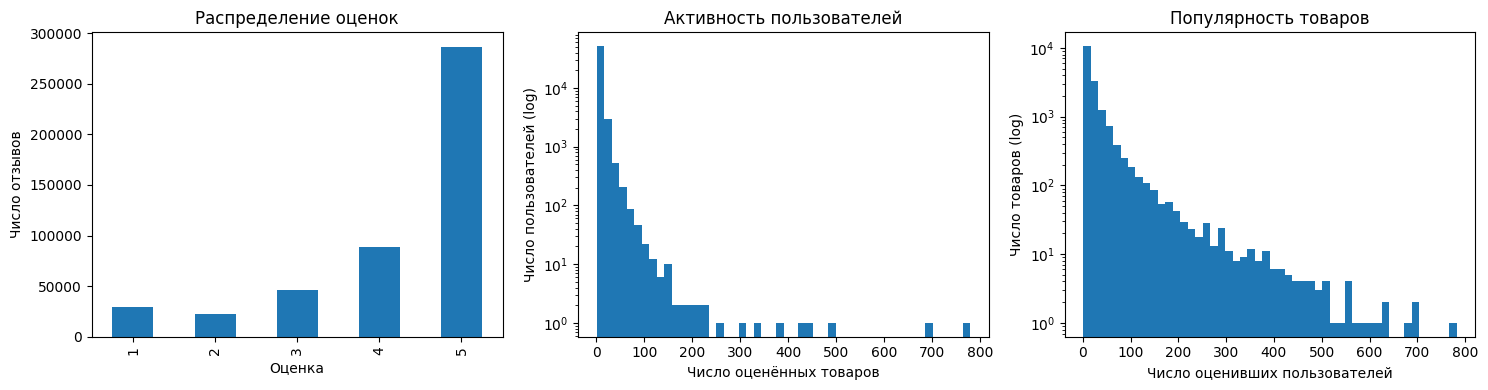

In [4]:
import matplotlib.pyplot as plt

rating_counts = reviews["overall"].value_counts().sort_index()
user_activity = reviews.groupby("reviewerID").size()
item_popularity = reviews.groupby("asin").size()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rating_counts.plot.bar(ax=axes[0])


axes[0].set(title="Распределение оценок", xlabel="Оценка", ylabel="Число отзывов")
axes[0].tick_params(axis="x")
axes[1].hist(user_activity, bins=50, log=True)
axes[1].set(title="Активность пользователей",xlabel="Число оценённых товаров",ylabel="Число пользователей (log)",)

axes[2].hist(item_popularity, bins=50, log=True)
axes[2].set(title="Популярность товаров",xlabel="Число оценивших пользователей",ylabel="Число товаров (log)", )

plt.tight_layout()
plt.show()

In [5]:
positive_share = reviews["overall"].ge(4).mean()
density = len(reviews) / (user_activity.size * item_popularity.size)
print(f"Доля положительных оценок: {positive_share:.1%}")
print(f"Разреженность матрицы: {1 - density:.4%}")
print(f"Пользователей с менее чем 5 товарами: {(user_activity < 5).sum():,}")

Доля положительных оценок: 79.2%
Разреженность матрицы: 99.9508%
Пользователей с менее чем 5 товарами: 4,277


Для каждой пары user–item оставлен первый отзыв. Поздние повторы не меняют раннюю историю. После удаления повторов у части пользователей осталось меньше пяти товаров, хотя исходная выборка была 5-core!


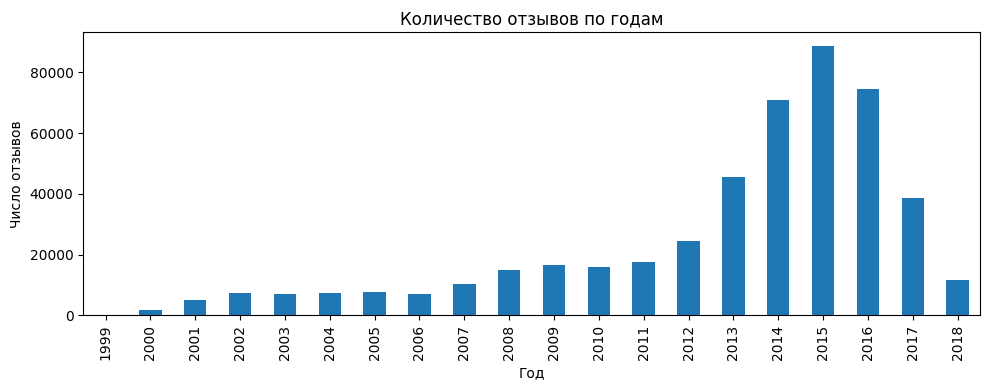

In [6]:
reviews.groupby(reviews["datetime"].dt.year).size().plot.bar(figsize=(10, 4),title="Количество отзывов по годам",xlabel="Год",ylabel="Число отзывов",)
plt.tight_layout()
plt.show()

## Временное разбиение

Отзывы распределены неравномерно: основная масса приходится на 2013-2017 годы, максимум в 2015 год. Тогда границы: train до 2016 года, validation 2016 год, test с 2017 года. 

In [7]:
train_end = pd.Timestamp("2016-01-01", tz="UTC")
valid_end = pd.Timestamp("2017-01-01", tz="UTC")

train = reviews[reviews["datetime"] < train_end].copy()
valid = reviews[(reviews["datetime"] >= train_end)& (reviews["datetime"] < valid_end)].copy()
test = reviews[reviews["datetime"] >= valid_end].copy()


pd.DataFrame([ { "split": name, "interactions": len(part), "users": part["reviewerID"].nunique(), "items": part["asin"].nunique(), } for name, part in [ ("train", train), ("validation", valid), ("test", test), ] ])

,split,interactions,users,items
0,train,348455,47864,16101
1,validation,74572,20607,11515
2,test,50400,15295,9929


Объёмы и границы периодов показаны выше. Будущие периоды не используются для обучения.


In [8]:
known_user = valid["reviewerID"].isin(train["reviewerID"])

known_item = valid["asin"].isin(train["asin"])


print(f"Новый пользователь: {(~known_user).mean():.1%} строк")
print(f"Новый товар: {(~known_item).mean():.1%} строк")
print(f"Знакомы оба: {(known_user & known_item).mean():.1%} строк")

Новый пользователь: 38.9% строк
Новый товар: 23.1% строк
Знакомы оба: 43.9% строк


In [9]:
valid_warm = valid[known_user & known_item].copy()

valid_positive = valid_warm[ valid_warm["overall"] >= 4 ].copy()

print("Взаимодействий для оценки:", len(valid_warm))
print("Положительных взаимодействий:", len(valid_positive))
print("Пользователей для оценки:", valid_positive["reviewerID"].nunique())

Взаимодействий для оценки: 32700
Положительных взаимодействий: 26293
Пользователей для оценки: 10616


Оцениваются только пользователи и товары, встречавшиеся в train (warm-start). Обучение использует весь train. Из рекомендаций исключаются уже оценённые товары, включая оценки 1–3. В оценку входят пользователи с хотя бы одним товаром в соответствующем периоде

In [10]:
metadata = pd.read_json(DATA_DIR / "meta_Video_Games.json.gz", lines=True,)

print("Строк метаданных:", len(metadata))
print("Уникальных товаров:", metadata["asin"].nunique())

metadata[["asin", "title", "category", "brand"]].head()

Строк метаданных: 84819
Уникальных товаров: 71911


,asin,title,category,brand
0,0042000742,Reversi Sensory Challenger,"[Video Games, PC, Games]",Fidelity Electronics
1,0078764343,Medal of Honor: Warfighter - Includes Battlefi...,"[Video Games, Xbox 360, Games, </span></span><...",by\n \n EA Games
2,0276425316,street fighter 2 II turbo super nintendo snes ...,"[Video Games, Retro Gaming & Microconsoles, Su...",Nintendo
3,0324411812,Xbox 360 MAS STICK,"[Video Games, Xbox 360, Accessories, Controlle...",by\n \n MAS SYSTEMS
4,0439335310,Phonics Alive! 3: The Speller,"[Video Games, PC, Games, </span></span></span>...",by\n \n Advanced Software Pty. Ltd.


In [11]:
import html
import re

def clean_text(value):
    if not isinstance(value, str):
        return ""
    value = html.unescape(value)
    value = re.sub(r"<[^>]+>", " ", value)
    return " ".join(value.split())


item_metadata = (
    metadata.loc[ metadata["asin"].isin(train["asin"]), ["asin", "title", "category", "brand"], ] .drop_duplicates("asin") .reset_index(drop=True)
)

item_metadata["title"] = item_metadata["title"].map(clean_text)

item_metadata["brand"] = (
    item_metadata["brand"] .map(clean_text) .str.replace(r"^by\s+", "", regex=True)
)

item_metadata["category"] = item_metadata["category"].map( lambda values: [ clean_text(value) for value in values if clean_text(value) ] if isinstance(values, list) else [] )

item_metadata.head()

,asin,title,category,brand
0,0700026657,Anno 2070,"[Video Games, PC, Games]",Ubisoft
1,0700026398,HITMAN ABSOLUTION (PC),"[Video Games, PC, Games]",Square Enix
2,0700099867,Dirt 3,"[Video Games, PC, Games]",Dirt 3
3,0804161380,Legend of Zelda Box Set Prima Official Game Guide,[],DIAMOND SELECT TOYS
4,3828770193,Foto Frenzy: Spot the Difference,"[Video Games, Kids & Family, Nintendo DS, Games]",Storm City Entertainment


Метаданные соединяются с товарами train по asin. Для каждого товара берётся первая запись справочника; HTML и лишние пробелы удаляются. Исторических версий метаданных в источнике нет.


In [12]:
missing_metadata = pd.Series({ "title": item_metadata["title"].eq("").sum(), "brand": item_metadata["brand"].eq("").sum(), "category": item_metadata["category"].map(len).eq(0).sum(), }, name="Пустых значений")

display(missing_metadata)

missing_items = (
    train["asin"].nunique()
    - item_metadata["asin"].nunique()
)

print("Товаров train совсем без метаданных:", missing_items)
display(item_metadata["brand"].replace("", pd.NA).value_counts().head(10))

display( item_metadata["category"] .explode() .value_counts() .head(15) )

title         0
brand       110
category    135
Name: Пустых значений, dtype: int64

Товаров train совсем без метаданных: 19


brand
Electronic Arts    1188
Activision         1004
Nintendo            966
Ubisoft             707
Sony                636
Microsoft           500
Sega                491
THQ                 369
Capcom              345
Square Enix         329
Name: count, dtype: int64

category
Video Games                     15947
Games                           11468
Retro Gaming & Microconsoles     4255
PC                               3691
Accessories                      3121
Kids & Family                    2503
Xbox 360                         1669
PlayStation 3                    1403
PlayStation 2                    1343
Wii                              1147
Nintendo DS                       983
Controllers                       596
PlayStation 4                     590
Xbox                              581
Xbox One                          518
Name: count, dtype: int64

In [13]:
catalog = (
    train[["asin"]] .drop_duplicates() .merge(item_metadata, on="asin", how="left", validate="one_to_one")
)
catalog["title"] = catalog["title"].fillna("Без названия")
catalog["brand"] = catalog["brand"].fillna("").replace("", "UNKNOWN")

catalog["category"] = catalog["category"].map( lambda values: ( list(dict.fromkeys(c for c in values if c != "Video Games")) or ["UNKNOWN"] ) if isinstance(values, list) else ["UNKNOWN"] )

catalog.head()

,asin,title,category,brand
0,B0000296O5,Final Fantasy VIII,"[Retro Gaming & Microconsoles, PlayStation, Ga...",SquareSoft
1,B00002NDRY,Age of Empires 2: Age of Kings - PC,"[PC, Games]",Microsoft
2,B00000JL6V,Riven: The Sequel to Myst - PC/Mac,"[PC, Games]",Ubisoft
3,B00000K1V2,South Park,"[Retro Gaming & Microconsoles, PlayStation, Ga...",Acclaim
4,B00000K4AX,System Shock 2 - PC,"[PC, Games]",Electronic Arts


Каталог содержит все товары train. Для отсутствующих названий используется «Без названия», для брендов и категорий — UNKNOWN. Общая категория Video Games удалена.


## Разреженная матрица положительной истории


Матрица положительных взаимодействий строится только по train; нули означают отсутствие положительного сигнала, а не подтверждённый дизлайк.


In [14]:
import numpy as np
from scipy.sparse import csr_matrix

user_ids = sorted(train["reviewerID"].unique())
item_ids = sorted(train["asin" ].unique())

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

positive_train = train[train["overall"] >= 4]

rows = positive_train["reviewerID"].map(user_to_idx).to_numpy()
cols = positive_train["asin"].map(item_to_idx).to_numpy() 


X_train = csr_matrix( (np.ones(len(positive_train), dtype=np.float32), (rows, cols)), shape=(len(user_ids), len( item_ids)), )

print("Размер матрицы:",  X_train.shape)
print("Положительных взаимодействий:",X_train.nnz)

Размер матрицы: (47864, 16101)
Положительных взаимодействий: 272375


## Оценка

Основная метрика для подбора — NDCG@10, дополнительная — Recall@10. NDCG учитывает позицию релевантного товара, Recall -- долю найденных релевантных товаров.

Кандидаты — весь каталог train. На validation исключается история train, на test исключается train + val. Товары с оценками 1–3 тоже исключаются. Настройки выбираются по val + перед test модели не переобучаются, чтобы сохранить общую обучающую базу и каталог.
Для ограничения времени ранжирования FM выбирается случайная выборка из 10 000 пользователей train. Отбор не использует будущие отзывы. В каждом периоде оцениваются участники выборки с доступным + ответом. Внутри периода аудитория одинакова для всех методов но между val и test она может различаться.

 Поля `rank`, `also_buy`, `also_view`, цены и тексты отзывов не используются.


In [15]:
import random
import time
import json
import platform
import scipy
import torch
from pathlib import Path
from scipy.sparse import csr_matrix
from evaluation import evaluate, recommend

SEED = 42
K = 10
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

u = train['reviewerID'].map(user_to_idx).to_numpy()
i = train['asin'].map(item_to_idx).to_numpy()
r = train['overall'].to_numpy(dtype=np.float32)
ratings_matrix = csr_matrix((r, (u, i)), shape=X_train.shape)
observed = ratings_matrix.copy()
observed.data[:] = 1
base_target = ratings_matrix.copy()
base_target.data = (base_target.data >= 4).astype(np.float32)

assert (base_target != X_train).nnz == 0

rng = np.random.default_rng(SEED)
cohort = set(rng.choice(len(user_ids), size=min(10000, len(user_ids)), replace=False).tolist())


def make_truth(part, seen):
    warm = part[part['reviewerID'].isin(user_to_idx) & part['asin'].isin(item_to_idx)]
    relevant = warm[warm['overall'] >= 4]
    truth = {}
    for uid, iid in zip(relevant['reviewerID'], relevant['asin']):
        user, item = user_to_idx[uid], item_to_idx[iid]
        if user in cohort and seen[user, item] == 0:
            truth.setdefault(user, set()).add(item)
    return truth

valid_truth = make_truth(valid, observed)
print('Validation: пользователей', len(valid_truth), 'релевантных пар', sum(map(len, valid_truth.values())))
print('Версии:', {'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__, 'pandas': pd.__version__, 'torch': torch.__version__})
print('Матрица:', X_train.shape, 'положительных:', X_train.nnz)


Validation: пользователей 2215 релевантных пар 5395
Версии: {'python': '3.12.0', 'numpy': '1.26.4', 'scipy': '1.13.1', 'pandas': '2.1.3', 'torch': '2.12.0'}
Матрица: (47864, 16101) положительных: 272375


## 1. ItemKNN

Бинарная матрица `X` содержит оценки 4–5. Сходство товаров это косинус их столбцов. Для каждого целевого товара оставляе `k` ближайших соседей, диагональ обнуляем. Оценка $\hat s_{uj}=\sum_i X_{ui}B_{ij}$. Неположительные оценки не формируют положительную историю, но исключаются из кандидатов.

Пространство поиска: `k = {40, 100}`. Обучение и ранжирование реализованы в `models/item_knn.py`

In [16]:
from models import ItemKNN

search_rows = []
best_models = {}
best_params = {}
validation_predictions = {}

for neighbors in [40, 100]:
    started = time.perf_counter()
    model = ItemKNN(k=neighbors).fit(X_train)
    metrics, per_user = evaluate(model, valid_truth, observed, K)
    search_rows.append({'model': 'ItemKNN', 'params': {'k': neighbors}, **metrics, 'seconds': time.perf_counter() - started})
    if ('ItemKNN' not in best_models
            or metrics['NDCG@10'] > validation_predictions['ItemKNN'][0]['NDCG@10']):
        best_models['ItemKNN'] = model
        best_params['ItemKNN'] = {'k': neighbors}
        validation_predictions['ItemKNN'] = metrics, per_user
    print(search_rows[-1], flush=True)

display(pd.DataFrame(search_rows))
assert best_models['ItemKNN'].B.diagonal().sum() == 0


{'model': 'ItemKNN', 'params': {'k': 40}, 'Recall@10': 0.020043141471291086, 'NDCG@10': 0.014382988142664893, 'users': 2215, 'seconds': 1.616735375020653}


{'model': 'ItemKNN', 'params': {'k': 100}, 'Recall@10': 0.02079958903467349, 'NDCG@10': 0.0149354039218411, 'users': 2215, 'seconds': 1.816125333076343}


,model,params,Recall@10,NDCG@10,users,seconds
0,ItemKNN,{'k': 40},0.020043,0.014383,2215,1.616735
1,ItemKNN,{'k': 100},0.020800,0.014935,2215,1.816125


## 2. iALS

Минимизация $\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2)$ по всем парам. Для наблюдаемой оценки `c_ui=1+α`,  На каждой итерации по очереди решаем нормальные уравнения для пользователей и товаров

`x_u = (Y.T Y + α Y_obs.T Y_obs + λ I)^(-1) ((1+α) Y_obs.T p_obs)`.

В коде используется `solve`, а не явное обращение матрицы. Ненаблюдаемые пары учтены через общую Gram-матрицу. Это взвешенная ALS для неявного предпочтения, полученного из явных оценок.

Пространство поиска: `factors = {16, 32}`, `reg ∈ {1, 10}`


In [17]:
from models import IALS

from itertools import product
for factors, regularization in product([16, 32], [1., 10.]):
    params = dict(factors=factors, reg=regularization, alpha=10., epochs=6, seed=SEED)
    started = time.perf_counter()
    model = IALS(**params).fit(observed, base_target)
    metrics, per_user = evaluate(model, valid_truth, observed, K)
    search_rows.append({'model': 'iALS', 'params': params, **metrics, 'seconds': time.perf_counter() - started})
    if ('iALS' not in best_models
            or metrics['NDCG@10'] > validation_predictions['iALS'][0]['NDCG@10']):
        best_models['iALS'] = model
        best_params['iALS'] = params
        validation_predictions['iALS'] = metrics, per_user
    print(search_rows[-1], flush=True)

display(pd.DataFrame(search_rows).query("model == 'iALS'"))


{'model': 'iALS', 'params': {'factors': 16, 'reg': 1.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.020369106596559442, 'NDCG@10': 0.01260151857435633, 'users': 2215, 'seconds': 8.27847941708751}


{'model': 'iALS', 'params': {'factors': 16, 'reg': 10.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.02094956451336047, 'NDCG@10': 0.012767389830542533, 'users': 2215, 'seconds': 8.340956542175263}


{'model': 'iALS', 'params': {'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.02879432862282697, 'NDCG@10': 0.017797806211994404, 'users': 2215, 'seconds': 10.280519958818331}


{'model': 'iALS', 'params': {'factors': 32, 'reg': 10.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.028783579402145466, 'NDCG@10': 0.017672757519042175, 'users': 2215, 'seconds': 10.331218625186011}


,model,params,Recall@10,NDCG@10,users,seconds
2,iALS,"{'factors': 16, 'reg': 1.0, 'alpha': 10.0, 'ep...",0.020369,0.012602,2215,8.278479
3,iALS,"{'factors': 16, 'reg': 10.0, 'alpha': 10.0, 'e...",0.020950,0.012767,2215,8.340957
4,iALS,"{'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'ep...",0.028794,0.017798,2215,10.280520
5,iALS,"{'factors': 32, 'reg': 10.0, 'alpha': 10.0, 'e...",0.028784,0.017673,2215,10.331219


## 3. SLIM

Восстановка положительной истории: $\min_B\frac12\|X-XB\|_F^2+\lambda_1\|B\|_1+\frac{\lambda_2}{2}\|B\|_F^2$, при `B≥0`, `diag(B)=0`. 

Для вычислительной доступности дополнительно разрешаем коэффициенты `B[i,j]` только для 60 ближайших к `j` товаров по train-косинусу. Получается SLIM с ограниченной поддержкой. Поддержка и все коэффициенты получены без будущих данных. Для каждой колонки решаем неотрицательную elastic-net задачу собственным координатным спуском. При `H=X_S.T X_S + λ2 I`, `b=X_S.T X_j - λ1` обновление: `w_k=max(0, w_k + (b-Hw)_k/H_kk)`.

Поиск: `λ1 = {1, 5}`, `λ2=10`


In [18]:
from models import SLIM

for l1 in [1., 5.]:
    params = dict(l1=l1, l2=10., neighbors=60, max_iter=60, tol=1e-4)
    started = time.perf_counter()
    model = SLIM(**params).fit(X_train)
    metrics, per_user = evaluate(model, valid_truth, observed, K)
    search_rows.append({'model': 'SLIM', 'params': params, **metrics, 'seconds': time.perf_counter() - started, 'converged_fraction': model.converged_fraction})
    assert model.B.diagonal().sum() == 0 and (model.B.data >= 0).all()
    if ('SLIM' not in best_models
            or metrics['NDCG@10'] > validation_predictions['SLIM'][0]['NDCG@10']):
        best_models['SLIM'] = model
        best_params['SLIM'] = params
        validation_predictions['SLIM'] = metrics, per_user
    print(search_rows[-1], flush=True)

display(pd.DataFrame(search_rows).query("model == 'SLIM'"))


{'model': 'SLIM', 'params': {'l1': 1.0, 'l2': 10.0, 'neighbors': 60, 'max_iter': 60, 'tol': 0.0001}, 'Recall@10': 0.027285725217467, 'NDCG@10': 0.019277065252219748, 'users': 2215, 'seconds': 5.6495637921616435, 'converged_fraction': 1.0}


{'model': 'SLIM', 'params': {'l1': 5.0, 'l2': 10.0, 'neighbors': 60, 'max_iter': 60, 'tol': 0.0001}, 'Recall@10': 0.02051255025215288, 'NDCG@10': 0.01552261799933394, 'users': 2215, 'seconds': 4.322474084096029, 'converged_fraction': 1.0}


,model,params,Recall@10,NDCG@10,users,seconds,converged_fraction
6,SLIM,"{'l1': 1.0, 'l2': 10.0, 'neighbors': 60, 'max_...",0.027286,0.019277,2215,5.649564,1.0
7,SLIM,"{'l1': 5.0, 'l2': 10.0, 'neighbors': 60, 'max_...",0.020513,0.015523,2215,4.322474,1.0


## 4. Факторизационная машина с метаданными

FM второго порядка: $s(x)=w_0+\sum_a w_a x_a+\sum_{a<b}\langle v_a,v_b\rangle x_a x_b$. Обучаем бинарной cross-entropy по логитам через PyTorch autograd, сами задаём все параметры и формулу FM.

Признаки: one-hot пользователя, товара, бренда и multi-hot категорий (платформа/тип товара). Дополнительно используются два категориальных признака пользователя: число train взаимодействий по фиксированным границам [5,10,20,50] и средняя оценка на трейне по фикс. границам [2,3,4,4.5]. Они доступны на момент обеих оценок, так как вычислены только по train.  Индексы признаков строятся по каталогу train, пустые значения — UNKNOWN, padding имеет индекс 0 и нулевой вектор. Все активные признаки имеют значение 1.

Все train-оценки используются как наблюдения: 4–5 значит 1, 1–3 значит 0. + на каждый положительный train-отзыв выбираем один случайный неоценённый в train товар как слабый отрицательный пример

Поиск: число факторов `{8,16}`

In [19]:
from models.fm import FM

ordered_catalog = catalog.set_index('asin').loc[item_ids]
feature_to_idx = {}
next_feature = 1 + len(user_ids) + len(item_ids)
feature_rows = []
for item_idx, row in enumerate(ordered_catalog.itertuples()):
    tokens = ['brand=' + row.brand] + ['category=' + c for c in row.category]
    feature_ids = [1 + len(user_ids) + item_idx]
    for token in tokens:
        if token not in feature_to_idx:
            feature_to_idx[token] = next_feature
            next_feature += 1
        feature_ids.append(feature_to_idx[token])
    feature_rows.append(feature_ids)

max_features = max(map(len, feature_rows))
item_features = np.zeros((len(item_ids), max_features), dtype=np.int64)
for idx, features in enumerate(feature_rows):
    item_features[idx, :len(features)] = features


print('Размер признаков товаров:', item_features.shape)
print('Брендов и категорий:', len(feature_to_idx))
print('Всего признаков с padding:', next_feature)
print('Пример:', ordered_catalog.iloc[0][['title', 'brand', 'category']].to_dict())
assert item_features.min() >= 0 and item_features.max() < next_feature


Размер признаков товаров: (16101, 21)
Брендов и категорий: 13154
Всего признаков с padding: 77120
Пример: {'title': 'HITMAN ABSOLUTION (PC)', 'brand': 'Square Enix', 'category': ['PC', 'Games']}


In [20]:
category_frequency = ordered_catalog['category'].explode().value_counts()
brand_frequency = ordered_catalog['brand'].value_counts()
print('Уникальных брендов:', len(brand_frequency))
print('Уникальных категорий:', len(category_frequency))
print('Категорий, встречающихся только у одного товара:', (category_frequency == 1).sum())
print('Примеры самых длинных категорий:')
for value in sorted(category_frequency.index, key=len, reverse=True)[:5]:
    print(len(value), repr(value[:180]))


Уникальных брендов: 1462
Уникальных категорий: 11692
Категорий, встречающихся только у одного товара: 10764
Примеры самых длинных категорий:
1757 "Take control of these authentically recreated steam, electric and diesel locomotives. Drive one of Amtrak's new high-speed electric trains on the busy North-east Corridor. Race alo"
1627 'F1 2013 PC (Includes Brand New Classic Content. 1980s content) Included 10 pages color printed installation manual with steam-online activation code on the back of the manual. Requ'
1607 'Brothers in Arms - Earned in Blood Features: Next chapter of Brothers In Arms - The award-winning WWII shooter returns with more of the action, story, and authenticity that has cri'
1416 'Plot[edit] Iraq launches an invasion of Kuwait on August 2, 1990. During an attempt to destroy one of the bridges crossing the Iraq-Kuwait border into Tierra Piedra, sniper Paul Fo'
1233 'Hitman Bloodmoney: Welcome to the USA Agent 47 is heading to the U.S. making deadly stops in iconic l

Были плохо удалены остаткиHTML разметки. Для FM оставляем категории длиной не более 80 символов, встречающиеся хотя бы у 5 товаров train. Остальные заменяем общей меткой OTHER. Бренды сохраняем. Порог и частоты не используют validation/test. Подготовленный ранее каталог остаётся источником названий для вывода.


In [21]:
allowed_categories = {
    category for category, count in category_frequency.items()
    if count >= 5 and len(category) <= 80
}
fm_catalog = ordered_catalog.copy()
fm_catalog['category'] = fm_catalog['category'].map( lambda values: list(dict.fromkeys( c if c in allowed_categories else 'OTHER' for c in values )) or ['UNKNOWN'] )

def build_item_features(with_metadata=True):
    vocabulary = {}
    offset = 1 + len(user_ids) + len(item_ids)
    feature_rows = []
    for item_idx, row in enumerate(fm_catalog.itertuples()):
        features = [1 + len(user_ids) + item_idx]
        tokens = ['brand=' + row.brand] + ['category=' + c for c in row.category]
        if with_metadata:
            for token in tokens:
                if token not in vocabulary:
                    vocabulary[token] = offset + len(vocabulary)
                    
                features.append(vocabulary[token])
        feature_rows.append(features)
    matrix = np.zeros((len(item_ids), max(map(len, feature_rows))), dtype=np.int64)
    for idx, features in enumerate(feature_rows):
        matrix[idx, :len(features)] = features
    return matrix, offset + len(vocabulary)

item_features, n_features = build_item_features()
print('Допустимых категорий:', len(allowed_categories))
print('Матрица признаков:', item_features.shape)
print('Всего признаков:', n_features)
assert n_features < next_feature

user_summary = train.groupby('reviewerID')['overall'].agg(['size', 'mean'])
user_summary = user_summary.loc[user_ids]
activity_bin = np.digitize(user_summary['size'].to_numpy(), [5, 10, 20, 50])
rating_bin = np.digitize(user_summary['mean'].to_numpy(), [2, 3, 4, 4.5])
user_feature_matrix = np.column_stack((n_features + activity_bin, n_features + 5 + rating_bin)).astype(np.int64)
n_features += 10
print('Признаки пользователя: активность и средняя оценка только по train; форма', user_feature_matrix.shape)


Допустимых категорий: 112
Матрица признаков: (16101, 14)
Всего признаков: 65541


Признаки пользователя: активность и средняя оценка только по train; форма (47864, 2)


In [22]:
fm_losses = {}
for factors in [8, 16]:
    params = dict(factors=factors, lr=.01, reg=1e-5, epochs=5, seed=SEED, batch_size=4096)
    started = time.perf_counter()
    model = FM(len(user_ids), item_features, n_features, user_features=user_feature_matrix, **params)
    model.fit(u, i, (r >= 4 ).astype(np.float32), observed)
    metrics, per_user = evaluate(model, valid_truth, observed, K)
    fm_losses[factors] = model.loss_history
    search_rows.append({'model': 'FM', 'params': params, **metrics, 'seconds': time.perf_counter() - started})
    if ('FM' not in best_models
            or metrics['NDCG@10'] > validation_predictions['FM'][0]['NDCG@10']):
        best_models['FM'] = model
        best_params['FM'] = params
        validation_predictions['FM'] = metrics, per_user
    print(search_rows[-1 ], 'loss: ', model.loss_history, flush=True)


display(pd.DataFrame(search_rows).query("model == 'FM'"))


{'model': 'FM', 'params': {'factors': 8, 'lr': 0.01, 'reg': 1e-05, 'epochs': 5, 'seed': 42, 'batch_size': 4096}, 'Recall@10': 0.008303105221841113, 'NDCG@10': 0.0055016229799992105, 'users': 2215, 'seconds': 18.57504079118371} loss:  [0.5943401057029349, 0.5162311448046737, 0.4716740402258977, 0.4429232172640498, 0.4232185140753515]


{'model': 'FM', 'params': {'factors': 16, 'lr': 0.01, 'reg': 1e-05, 'epochs': 5, 'seed': 42, 'batch_size': 4096}, 'Recall@10': 0.009417082791800624, 'NDCG@10': 0.005422040688066212, 'users': 2215, 'seconds': 26.736284125130624} loss:  [0.5842282820360072, 0.5033357581298414, 0.4627170949133125, 0.4344435871555666, 0.4129620706639704]


,model,params,Recall@10,NDCG@10,users,seconds,converged_fraction
8,FM,"{'factors': 8, 'lr': 0.01, 'reg': 1e-05, 'epoc...",0.008303,0.005502,2215,18.575041,NaN
9,FM,"{'factors': 16, 'lr': 0.01, 'reg': 1e-05, 'epo...",0.009417,0.005422,2215,26.736284,NaN


FM ID-only: {'Recall@10': 0.0108345304056365, 'NDCG@10': 0.006986775287241437, 'users': 2215} seconds: 8.69725687499158
FM + metadata: {'Recall@10': 0.008303105221841113, 'NDCG@10': 0.0055016229799992105, 'users': 2215}


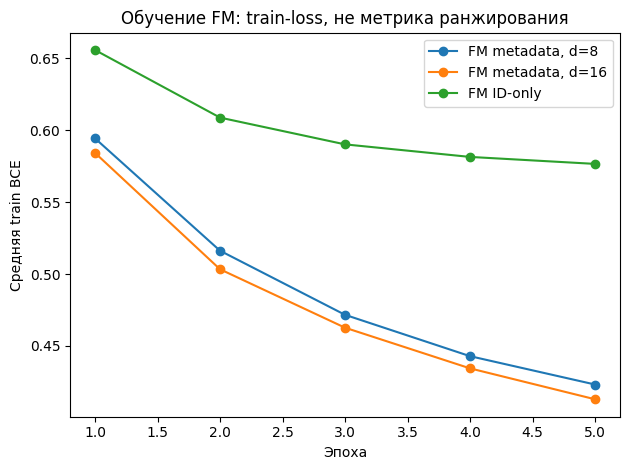

In [23]:
id_features, n_id_features = build_item_features(with_metadata=False)
started = time.perf_counter()
fm_id_only = FM(len(user_ids), id_features, n_id_features, **best_params['FM'])
fm_id_only.fit(u, i, (r >= 4).astype(np.float32), observed)
id_metrics, id_per_user = evaluate(fm_id_only, valid_truth, observed, K)
print('FM ID-only:', id_metrics, 'seconds:', time.perf_counter() - started)
print('FM + metadata:', validation_predictions['FM'][0])

for factors, losses in fm_losses.items():
    plt.plot(range(1, len(losses) + 1), losses, marker='o', label=f'FM metadata, d={factors}')
plt.plot(range(1, len(fm_id_only.loss_history) + 1), fm_id_only.loss_history, marker='o', label='FM ID-only')
plt.xlabel('Эпоха')
plt.ylabel('Средняя train BCE')
plt.title('Обучение FM: train-loss, не метрика ранжирования')
plt.legend()
plt.tight_layout()
plt.show()


## 5. ALS с собственным целевым сигналом

Бинарный таргет базового iALS одинаково трактует оценки 4 и 5, а оценки 1–3 объединяет с 0. Вместо бинарного таргета используется оценка:

$p_{ui}=(r_{ui}-3)/2$ для наблюдаемых оценок, `0` для ненаблюдаемых пар.

Соответствие: 1 -> −1; 2 -> −0.5; 3 -> 0; 4 -> 0.5; 5 -> 1. Низкие оценки явно отталкивают факторные представления, а 5 даёт более сильный положительный таргет, чем 4. Наблюдаемая тройка и отсутствующая оценка имеют одинаковый таргет 0, но разную уверенность, как и в базовой постановке.

Постановка как в пункте 4

In [24]:
from models import CustomALS

from itertools import product
for factors, regularization in product([16, 32], [1., 10.]):
    params = dict(factors=factors, reg=regularization, alpha=10., epochs=6, seed=SEED)
    started = time.perf_counter()
    model = CustomALS(**params).fit(observed, ratings_matrix)
    metrics, per_user = evaluate(model, valid_truth, observed, K)
    search_rows.append({'model': 'CustomALS', 'params': params, **metrics, 'seconds': time.perf_counter() - started})
    if ('CustomALS' not in best_models
            or metrics['NDCG@10'] > validation_predictions['CustomALS'][0]['NDCG@10']):
        best_models['CustomALS'] = model
        best_params['CustomALS'] = params
        validation_predictions['CustomALS'] = metrics, per_user
    print(search_rows[-1], flush=True)


matched_comparison = pd.DataFrame([ {'model': row['model'], 'factors': row['params']['factors'], 'reg': row['params']['reg'], 'NDCG@10': row['NDCG@10'], 'Recall@10': row['Recall@10']} for row in search_rows if row['model'] in ['iALS', 'CustomALS'] ])
display(matched_comparison)


{'model': 'CustomALS', 'params': {'factors': 16, 'reg': 1.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.021810836819922075, 'NDCG@10': 0.012872998691885363, 'users': 2215, 'seconds': 8.29678774997592}


{'model': 'CustomALS', 'params': {'factors': 16, 'reg': 10.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.021434614096069553, 'NDCG@10': 0.012718039016362072, 'users': 2215, 'seconds': 8.210900374921039}


{'model': 'CustomALS', 'params': {'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.023770055593710798, 'NDCG@10': 0.015170445495006369, 'users': 2215, 'seconds': 10.484414333011955}


{'model': 'CustomALS', 'params': {'factors': 32, 'reg': 10.0, 'alpha': 10.0, 'epochs': 6, 'seed': 42}, 'Recall@10': 0.02313166503492105, 'NDCG@10': 0.015060340858642732, 'users': 2215, 'seconds': 10.710708624916151}


,model,factors,reg,NDCG@10,Recall@10
0,iALS,16,1.0,0.012602,0.020369
1,iALS,16,10.0,0.012767,0.020950
2,iALS,32,1.0,0.017798,0.028794
3,iALS,32,10.0,0.017673,0.028784
4,CustomALS,16,1.0,0.012873,0.021811
5,CustomALS,16,10.0,0.012718,0.021435
6,CustomALS,32,1.0,0.015170,0.023770
7,CustomALS,32,10.0,0.015060,0.023132


## Выбор настроек

Лучшие параметры выбираются по validation NDCG@10 и сохраняются вместе со всеми результатами поиска. Далее выполняется оценка на test без изменения настроек.


In [25]:
from models.popularity import Popularity
popularity = Popularity().fit(X_train)
pop_metrics, pop_per_user = evaluate(popularity, valid_truth, observed, K)
best_models['Popularity'] = popularity
best_params['Popularity'] = {}
validation_predictions['Popularity'] = pop_metrics, pop_per_user
model_order = ['Popularity', 'ItemKNN', 'iALS', 'SLIM', 'FM', 'CustomALS']
validation_table = pd.DataFrame([ {'model': name, **validation_predictions[name][0], 'params': best_params[name]} for name in model_order ])
display(validation_table.sort_values('NDCG@10', ascending=False))

pd.DataFrame(search_rows).to_csv(RESULTS_DIR / 'validation_search.csv', index=False)
config = {
    'seed': SEED, 'K': K, 'primary_metric': 'NDCG@10',
    'dataset_files': json.loads((DATA_DIR.parent / 'download_manifest.json').read_text())['files'],
    'positive_rating_min': 4, 'train_end': str(train_end), 'valid_end': str(valid_end),
    'cohort_train_user_indices': sorted(cohort),
    'metadata_category_min_items': 5, 'metadata_category_max_length': 80,
    'deduplication': 'first interaction per user-item',
    'user_features': {'activity_bins': [5,10,20,50], 'mean_rating_bins': [2,3,4,4.5]},
    'refit_on_validation': False, 'best_params': best_params,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'scipy': scipy.__version__, 'pandas': pd.__version__,
                 'torch': torch.__version__},
}

(RESULTS_DIR / 'experiment_config.json').write_text( json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8' )
assert len(best_models) == 6

print('Настройки зафиксированы. Validation-лидер:', validation_table.loc[validation_table['NDCG@10'].idxmax(), 'model'])


,model,Recall@10,NDCG@10,users,params
3,SLIM,0.027286,0.019277,2215,"{'l1': 1.0, 'l2': 10.0, 'neighbors': 60, 'max_..."
2,iALS,0.028794,0.017798,2215,"{'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'ep..."
5,CustomALS,0.023770,0.015170,2215,"{'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'ep..."
1,ItemKNN,0.020800,0.014935,2215,{'k': 100}
4,FM,0.008303,0.005502,2215,"{'factors': 8, 'lr': 0.01, 'reg': 1e-05, 'epoc..."
0,Popularity,0.007886,0.004288,2215,{}


Настройки зафиксированы. Validation-лидер: SLIM


## Оценка на test

Из кандидатов исключаются все товары, оценённые пользователем в train и val. Параметры моделей остаются обученными на train

In [26]:
valid_known = valid[
    valid['reviewerID'].isin(user_to_idx) & valid['asin'].isin(item_to_idx)
]
valid_seen = csr_matrix( (np.ones(len(valid_known), dtype=np.float32), (valid_known['reviewerID'].map(user_to_idx), valid_known['asin'].map(item_to_idx))), shape=observed.shape, )
seen_test = (observed + valid_seen).tocsr()
seen_test.data[:] = 1

def coverage_row(name, part, seen):
    known_u = part['reviewerID'].isin(user_to_idx)
    known_i = part['asin'].isin(item_to_idx)
    truth = make_truth(part, seen)
    return {'split': name, 'all_interactions': len(part),
            'new_user_rows_pct': 100 * (~known_u).mean(),
            'new_item_rows_pct': 100 * (~known_i).mean(),
            'warm_interactions': int((known_u & known_i).sum()),
            'evaluated_users_in_cohort': len(truth),
            'evaluated_positive_pairs': sum(map(len, truth.values()))}

test_truth = make_truth(test, seen_test)
coverage_table = pd.DataFrame([ coverage_row('validation', valid, observed), coverage_row('test', test, seen_test), ])
display(coverage_table)
coverage_table.to_csv(RESULTS_DIR / 'evaluation_coverage.csv', index=False)
print('Пользователей test:', len(test_truth))
assert len(test_truth) > 0


,split,all_interactions,new_user_rows_pct,new_item_rows_pct,warm_interactions,evaluated_users_in_cohort,evaluated_positive_pairs
0,validation,74572,38.871158,23.118597,32700,2215,5395
1,test,50400,48.456349,32.178571,16029,1171,2507


Пользователей test: 1171


In [27]:
test_predictions = {}
final_rows = []
for name in model_order:
    started = time.perf_counter()
    metrics, per_user = evaluate(best_models[name], test_truth, seen_test, K)
    test_predictions[name] = metrics, per_user
    final_rows.append({ 'model': name, 'validation_NDCG@10': validation_predictions[name][0]['NDCG@10'], 'validation_Recall@10': validation_predictions[name][0]['Recall@10'], 'test_NDCG@10': metrics['NDCG@10'], 'test_Recall@10': metrics['Recall@10'], 'test_users': metrics['users'], 'params': best_params[name], })
    print(name, metrics, 'evaluation_seconds:', time.perf_counter() - started, flush=True)

final_table = pd.DataFrame(final_rows).sort_values('test_NDCG@10', ascending=False)
display(final_table)
final_table.to_csv(RESULTS_DIR / 'final_comparison.csv', index=False)
reference_users = test_predictions['ItemKNN'][1][:, 0]
assert all(np.array_equal(reference_users, result[1][:, 0]) for result in test_predictions.values())


Popularity {'Recall@10': 0.014542957753888582, 'NDCG@10': 0.007474398531839245, 'users': 1171} evaluation_seconds: 1.6974229160696268


ItemKNN {'Recall@10': 0.015464329768343435, 'NDCG@10': 0.01048030916010365, 'users': 1171} evaluation_seconds: 0.7712929579429328


iALS {'Recall@10': 0.02328943947218926, 'NDCG@10': 0.013750258768353637, 'users': 1171} evaluation_seconds: 1.6147294999100268


SLIM {'Recall@10': 0.023063248703726925, 'NDCG@10': 0.01630482779050741, 'users': 1171} evaluation_seconds: 0.525871291058138


FM {'Recall@10': 0.015542563044697973, 'NDCG@10': 0.008247836220683018, 'users': 1171} evaluation_seconds: 8.418265291955322


CustomALS {'Recall@10': 0.025432499941466638, 'NDCG@10': 0.014204835572592453, 'users': 1171} evaluation_seconds: 1.6954624999780208


,model,validation_NDCG@10,validation_Recall@10,test_NDCG@10,test_Recall@10,test_users,params
3,SLIM,0.019277,0.027286,0.016305,0.023063,1171,"{'l1': 1.0, 'l2': 10.0, 'neighbors': 60, 'max_..."
5,CustomALS,0.015170,0.023770,0.014205,0.025432,1171,"{'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'ep..."
2,iALS,0.017798,0.028794,0.013750,0.023289,1171,"{'factors': 32, 'reg': 1.0, 'alpha': 10.0, 'ep..."
1,ItemKNN,0.014935,0.020800,0.010480,0.015464,1171,{'k': 100}
4,FM,0.005502,0.008303,0.008248,0.015543,1171,"{'factors': 8, 'lr': 0.01, 'reg': 1e-05, 'epoc..."
0,Popularity,0.004288,0.007886,0.007474,0.014543,1171,{}


## Различия между моделями

Для сравнения используется парный бутстреп по пользователям: одни и те же пользовательские разности пересэмплируются 2000 раз. Интервалы отражают вариацию аудитории на фиксированном сплите, но не разброс обучения и подбора параметров. Поправка на множественные сравнения не применяется.


In [28]:
id_test_metrics, id_test_per_user = evaluate(fm_id_only, test_truth, seen_test, K)
ablation_table = pd.DataFrame([ {'variant': 'FM + metadata', 'split': 'validation', **validation_predictions['FM'][0]}, {'variant': 'FM ID-only', 'split': 'validation', **id_metrics}, {'variant': 'FM + metadata', 'split': 'test', **test_predictions['FM'][0]}, {'variant': 'FM ID-only', 'split': 'test', **id_test_metrics}, ])
display(ablation_table)
ablation_table.to_csv(RESULTS_DIR / 'fm_ablation.csv', index=False)

def paired_interval(first, second, metric_column=2, repeats=2000):
    assert np.array_equal(first[:, 0], second[:, 0])
    differences = first[:, metric_column] - second[:, metric_column]
    rng = np.random.default_rng(SEED)
    means = np.array([ rng.choice(differences, size=len(differences), replace=True).mean() for _ in range(repeats) ])
    low, high = np.quantile(means, [.025, .975])
    return {'difference': differences.mean(), 'CI_low': low, 'CI_high': high}

interval_rows = []
for first, second in [('SLIM', 'iALS'), ('CustomALS', 'iALS')]:
    for metric, column in [('NDCG@10', 2), ('Recall@10', 1)]:
        interval_rows.append({'comparison': first + ' − ' + second, 'metric': metric, **paired_interval(test_predictions[first][1], test_predictions[second][1], column)})
interval_rows.append({'comparison': 'FM metadata − FM ID-only', 'metric': 'NDCG@10', **paired_interval(test_predictions['FM'][1], id_test_per_user)})
interval_table = pd.DataFrame(interval_rows)
display(interval_table)
interval_table.to_csv(RESULTS_DIR / 'paired_bootstrap.csv', index=False)


,variant,split,Recall@10,NDCG@10,users
0,FM + metadata,validation,0.008303,0.005502,2215
1,FM ID-only,validation,0.010835,0.006987,2215
2,FM + metadata,test,0.015543,0.008248,1171
3,FM ID-only,test,0.015548,0.008588,1171


,comparison,metric,difference,CI_low,CI_high
0,SLIM − iALS,NDCG@10,0.002555,-0.002586,0.007980
1,SLIM − iALS,Recall@10,-0.000226,-0.008431,0.008147
2,CustomALS − iALS,NDCG@10,0.000455,-0.002033,0.003054
3,CustomALS − iALS,Recall@10,0.002143,-0.003132,0.007723
4,FM metadata − FM ID-only,NDCG@10,-0.000340,-0.003978,0.003324


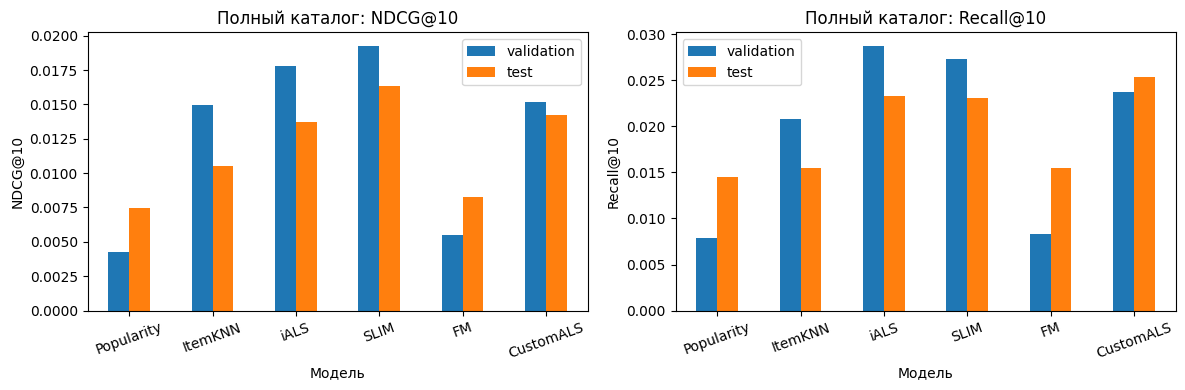

Все выбранные гиперпараметры:
{
  "ItemKNN": {
    "k": 100
  },
  "iALS": {
    "factors": 32,
    "reg": 1.0,
    "alpha": 10.0,
    "epochs": 6,
    "seed": 42
  },
  "SLIM": {
    "l1": 1.0,
    "l2": 10.0,
    "neighbors": 60,
    "max_iter": 60,
    "tol": 0.0001
  },
  "FM": {
    "factors": 8,
    "lr": 0.01,
    "reg": 1e-05,
    "epochs": 5,
    "seed": 42,
    "batch_size": 4096
  },
  "CustomALS": {
    "factors": 32,
    "reg": 1.0,
    "alpha": 10.0,
    "epochs": 6,
    "seed": 42
  },
  "Popularity": {}
}


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_table = final_table.set_index('model').loc[model_order]
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    plot_table[[f'validation_{metric}', f'test_{metric}']].rename( columns={f'validation_{metric}': 'validation', f'test_{metric}': 'test'} ).plot.bar(ax=ax, rot=20)
    ax.set_ylabel(metric)
    ax.set_xlabel('Модель')
    ax.set_title(f'Полный каталог: {metric}')
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'comparison.png', dpi=160, bbox_inches='tight')
plt.show()

print('Все выбранные гиперпараметры:')
print(json.dumps(best_params, ensure_ascii=False, indent=2))


## Пример рекомендаций

Выбран пользователь с минимальным индексом в test-аудитории. Для каждого метода сохраняются top-10 и проверяется отсутствие известных товаров. Ниже рекомендации SLIM и релевантные товары ему


In [30]:
example_user = min(test_truth)
example_rows = []
for name in model_order:
    recs = recommend(best_models[name], [example_user], seen_test, K)[0]
    assert len(set(recs.tolist())) == K
    assert all(seen_test[example_user, item] == 0 for item in recs)
    for rank, item in enumerate(recs, start=1):
        example_rows.append({'model': name, 'rank': rank, 'asin': item_ids[item], 'relevant_in_test': item in test_truth[example_user]})

example_table = pd.DataFrame(example_rows).merge( catalog[['asin', 'title', 'brand']], on='asin', how='left', validate='many_to_one' )
example_table.to_csv(RESULTS_DIR / 'example_recommendations.csv', index=False)
print('Индекс пользователя:', example_user)
display(example_table[example_table['model'] == 'SLIM'])
print('Релевантные товары этого пользователя в test:')
display(catalog[catalog['asin'].isin( [item_ids[item] for item in sorted(test_truth[example_user])] )][['asin', 'title', 'brand']])


Индекс пользователя: 0


,model,rank,asin,relevant_in_test,title,brand
30,SLIM,1,B000TLU67W,False,PlayStation 2 Console Slim PS2,Sony
31,SLIM,2,B00008KTRS,False,Shin Megami Tensei: Digital Devil Saga - PlayS...,Atlus
32,SLIM,3,B000784XG2,False,Shin Megami Tensei Digital Devil Saga 2 - Play...,Atlus
33,SLIM,4,B0014CN2H6,False,Shin Megami Tensei: Persona 3 FES - PlayStation 2,Atlus
34,SLIM,5,B00005T7ZN,False,Shadow Hearts,Midway
35,SLIM,6,B000FPM4WC,False,Shin Megami Tensei: Persona 3 - PlayStation 2,Atlus
36,SLIM,7,B002VA593A,False,Shin Megami Tensei: Strange Journey - Nintendo DS,Atlus
37,SLIM,8,B000G7X5P4,False,Valkyrie Profile 2: Silmeria - PlayStation 2,Square Enix
38,SLIM,9,B006YDPU48,False,Dark Souls II - Playstation 3,Bandai Namco Entertainment America
39,SLIM,10,B0002GTFIK,False,Star Ocean Till the End of Time - PlayStation 2,Square Enix


Релевантные товары этого пользователя в test:


,asin,title,brand
14766,B00SUUTSA0,SADES A60S/OMG PC Wired USB Stereo Gaming Head...,SADES


## Выводы

SLIM получил наибольший test NDCG@10 = 0,01630. При этом 95% bootstrap-интервал разницы SLIM−iALS [−0,00259; 0,00798] включает ноль. Подтверждённого превосходства над iALS на этой аудитории нет. По Recall@10 первым оказался CustomALS с результатом 0,02543.

Для iALS и CustomALS на validation выбраны одинаковые настройки: 32 фактора и reg=1. CustomALS немного лучше на test по обеим метрикам, но оба интервала разности включают ноль. Кастомный сигнал не дал подтверждённого улучшения.

Популярность получила test NDCG@10=0,00747. Результат SLIM примерно в 2,18 раза выше. FM с метапризнаками получила 0,00825 и лишь немного опередила популярность. Интервалы этих сравнений с baseline отдельно не рассчитывались.

У FM на ID-only test NDCG@10=0,00859, у варианта с метапризнаками = 0,00825. Интервал разности [−0,00398; 0,00332] включает ноль. Добавление признаков не дало подтверждённого выигрыша. Вклад бренда, категорий и активности по отдельности не измерялся. Шум метаданных, небольшой поиск и обучение через BCE могут влиять на результат, но этот эксперимент не позволяет установить причину.

У FM и популярности test-метрики выше validation, у остальных методов ниже. Аудитории периодов различаются, поэтому связать изменение только с устареванием моделей нельзя.

### Ограничения

Сравнение проведено на одном временном разбиении и с одним seed. Оценивались только знакомые пользователи и товары, а для сокращения времени расчёта использовалась случайная когорта пользователей. Пространство поиска было небольшим, поддержка SLIM ограничивалась ближайшими соседями.
